In [8]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.axes._axes import _log as matplotlib_axes_logger
from mpl_toolkits import mplot3d
from sklearn.model_selection import train_test_split
from sklearn.svm import SVC
from matplotlib.colors import ListedColormap

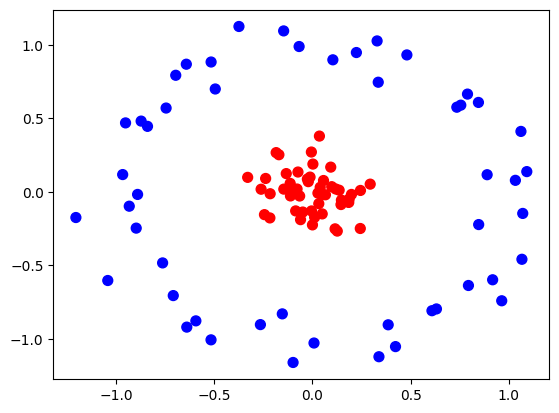

In [13]:
from sklearn.datasets import make_circles
X, y = make_circles(100, factor=.1, noise=.1)

plt.scatter(X[:, 0], X[:, 1], c=y, s=50, cmap='bwr')

In [49]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size = 0.20)

In [50]:
classifier = SVC(kernel="linear")
classifier.fit(X_train, y_train.ravel())
y_pred = classifier.predict(X_test)

In [51]:
from sklearn.metrics import accuracy_score
accuracy_score(y_test, y_pred)

0.45

In [48]:
zero_one_colourmap = ListedColormap(('blue', 'red'))
def plot_decision_boundary(X, y, clf):
    X_set, y_set = X, y
    X1, X2 = np.meshgrid(np.arange(start = X_set[:, 0].min() - 1, 
                                 stop = X_set[:, 0].max() + 1, 
                                 step = 0.01),
                       np.arange(start = X_set[:, 1].min() - 1, 
                                 stop = X_set[:, 1].max() + 1, 
                                 step = 0.01))
  
    plt.contourf(X1, X2, clf.predict(np.array([X1.ravel(), 
                                             X2.ravel()]).T).reshape(X1.shape),
               alpha = 0.75, 
               cmap = zero_one_colourmap)
    plt.xlim(X1.min(), X1.max())
    plt.ylim(X2.min(), X2.max())
    for i, j in enumerate(np.unique(y_set)):
        plt.scatter(X_set[y_set == j, 0], X_set[y_set == j, 1],
                c = (zero_one_colourmap)(i), label = j)
    plt.title('SVM Decision Boundary')
    plt.xlabel('X1')
    plt.ylabel('X2')
    plt.legend()
    return plt.show()

C:\Users\LOQ\AppData\Local\Temp\ipykernel_6728\3603277588.py:18: UserWarning: *c* argument looks like a single numeric RGB or RGBA sequence, which should be avoided as value-mapping will have precedence in case its length matches with *x* & *y*.  Please use the *color* keyword-argument or provide a 2D array with a single row if you intend to specify the same RGB or RGBA value for all points.
  plt.scatter(X_set[y_set == j, 0], X_set[y_set == j, 1],


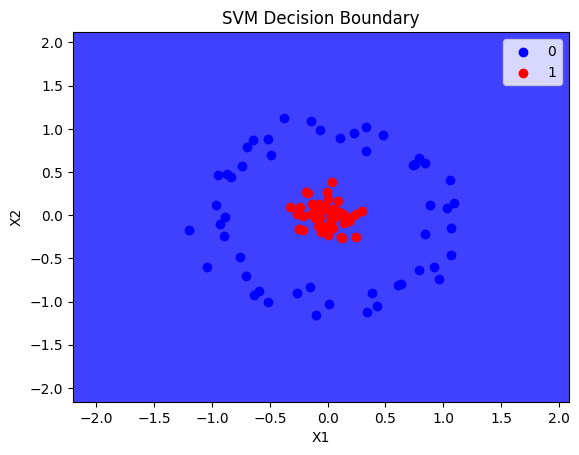

In [37]:
plot_decision_boundary(X, y, classifier)

In [52]:
def plot_3d_plot(X, y):
    r = np.exp(-(X ** 2).sum(1))
    ax = plt.subplot(projection='3d')
    ax.scatter3D(X[:, 0], X[:, 1], r, c=y, s=100, cmap='bwr')
    ax.set_xlabel('X1')
    ax.set_ylabel('X2')
    ax.set_zlabel('y')
    return ax

<Axes3D: xlabel='X1', ylabel='X2', zlabel='y'>

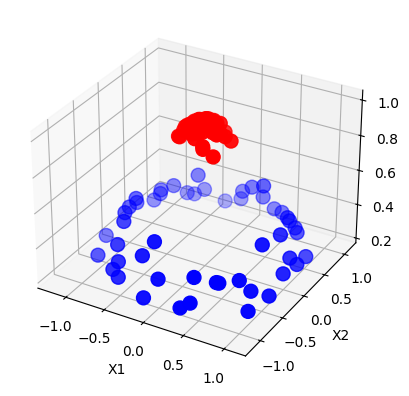

In [53]:
plot_3d_plot(X,y)

In [54]:
rbf_classifier = SVC(kernel="rbf")
rbf_classifier.fit(X_train, y_train)
y_pred = rbf_classifier.predict(X_test)

In [55]:
accuracy_score(y_test, y_pred)

1.0

C:\Users\LOQ\AppData\Local\Temp\ipykernel_6728\3603277588.py:18: UserWarning: *c* argument looks like a single numeric RGB or RGBA sequence, which should be avoided as value-mapping will have precedence in case its length matches with *x* & *y*.  Please use the *color* keyword-argument or provide a 2D array with a single row if you intend to specify the same RGB or RGBA value for all points.
  plt.scatter(X_set[y_set == j, 0], X_set[y_set == j, 1],


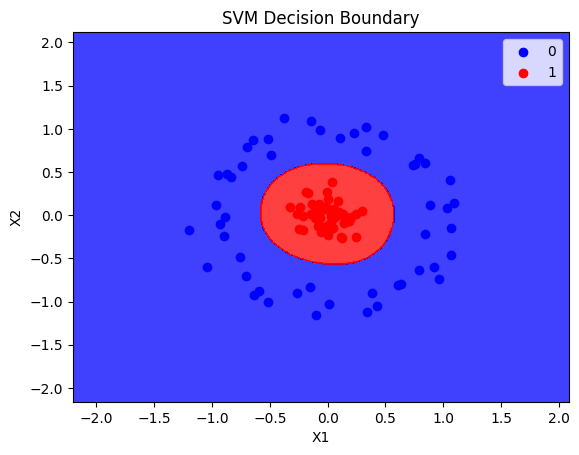

In [56]:
plot_decision_boundary(X, y, rbf_classifier)

In [93]:
poly_classifier = SVC(kernel="poly",degree=2)
poly_classifier.fit(X_train, y_train)
y_pred = poly_classifier.predict(X_test)

In [94]:
accuracy_score(y_test, y_pred)

1.0

C:\Users\LOQ\AppData\Local\Temp\ipykernel_6728\3603277588.py:18: UserWarning: *c* argument looks like a single numeric RGB or RGBA sequence, which should be avoided as value-mapping will have precedence in case its length matches with *x* & *y*.  Please use the *color* keyword-argument or provide a 2D array with a single row if you intend to specify the same RGB or RGBA value for all points.
  plt.scatter(X_set[y_set == j, 0], X_set[y_set == j, 1],


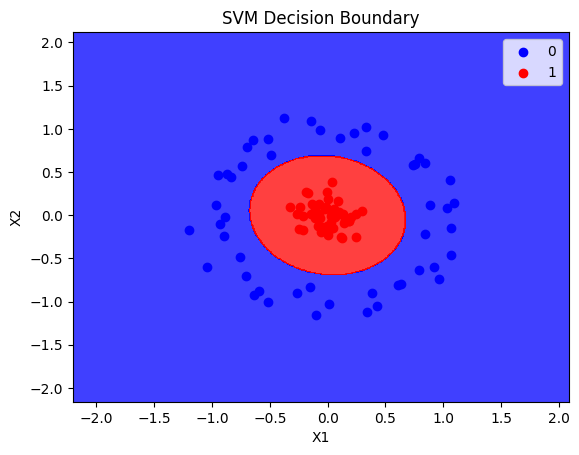

In [95]:
plot_decision_boundary(X, y, poly_classifier)

In [83]:
X

array([[ 6.31283475e-01, -7.96251004e-01],
       [-6.39108433e-01, -9.19903197e-01],
       [ 2.23919092e-01,  9.47016807e-01],
       [ 5.65642136e-02,  7.68296891e-02],
       [-2.54834698e-02,  8.67815304e-02],
       [ 3.38706592e-01, -1.12123996e+00],
       [ 1.82998859e-01, -6.92542467e-02],
       [-5.15778562e-01, -1.00638943e+00],
       [ 4.81439588e-02, -2.06746921e-02],
       [-1.84308801e-01,  2.66541872e-01],
       [-9.31848612e-01, -9.77949736e-02],
       [-6.41453843e-01,  8.67629873e-01],
       [ 8.89225602e-01,  1.16307297e-01],
       [-1.32945539e-01,  1.23912784e-01],
       [ 7.89314209e-01,  6.64448766e-01],
       [ 3.98096824e-02,  3.05581471e-02],
       [-1.19274004e-02,  1.00062594e-01],
       [-8.96457406e-01, -2.46847531e-01],
       [-5.92888772e-01, -8.77354942e-01],
       [-1.46176974e-01,  1.09399982e+00],
       [ 7.34987597e-01,  5.75261887e-01],
       [ 4.99795602e-02, -1.50206079e-01],
       [-2.16236551e-01, -1.77526744e-01],
       [-1.

In [62]:
np.exp(-(X**2)).sum(1)

array([1.20177102, 1.09370614, 1.3589526 , 1.99092019, 1.99184806,
       1.17606917, 1.96228129, 1.12961148, 1.99725749, 1.89802114,
       1.41012855, 1.13373446, 1.44008086, 1.96724366, 1.17940008,
       1.99748308, 1.98989518, 1.38858384, 1.16674787, 1.28100778,
       1.30088592, 1.97519591, 1.92329378, 1.20494214, 1.43604572,
       1.96121288, 1.20783809, 1.15230189, 1.34752161, 1.96320693,
       1.03344136, 1.2137739 , 1.9991249 , 1.16904319, 1.97520197,
       1.92938724, 1.94182632, 1.98561687, 1.97609519, 1.91436379,
       1.95069316, 1.92533182, 1.13045384, 1.44031212, 1.28538852,
       1.35106556, 1.30332141, 1.9788992 , 1.97875931, 1.98150858,
       1.45303208, 1.98320006, 1.99480093, 1.46773328, 1.99245125,
       1.13112467, 0.97286814, 1.95470838, 1.24626268, 1.22565494,
       1.21083951, 1.19887602, 1.31491779, 1.2140489 , 1.91530896,
       1.39666496, 1.99518982, 1.26157795, 1.38016869, 1.887652  ,
       1.25059201, 1.99357988, 1.86497445, 1.93678757, 1.29757

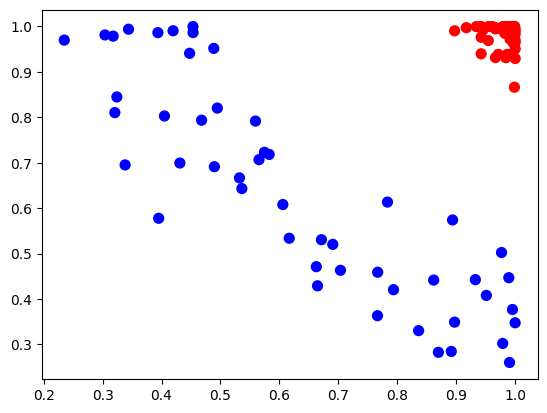

In [63]:
X_new=np.exp(-(X**2))
plt.scatter(X_new[:, 0], X_new[:, 1], c=y, s=50, cmap='bwr')